# B2B Sales Forecasting

# 1. Business Understanding

## Background  

SIEMENS is a German multinational technology conglomerate that has a wide range of technology solutions to provide for companies. They operate in the B2B (Business to Business) market to provide companies with the necessary technologies for them to scale, always ensuring their needs are met. <br>  
SIEMENS contacted our team to make a sales forecast of their revenue for the next 10 months in order to ensure that this work is not handled manually by an individual, which is subject to human error. A Machine Learning model, while still capable of some imperfections, is not affected by human error per se.  

## Business Objectives  

Based on the background presented above, the main objective of our initiative is to **develop a machine learning algorithm that is capable of accurately predicting the sales of SIEMENS for the next 10 months**.  

### Sub-Objectives (SBOs)  
Additionally, to our main goal, another set of sub-objectives is defined to ensure that our solution aligns with the business concept and intentions of the company. These are the following:  

- **SBO1**: Reduce Days on Hand by 2%.  
- **SBO2**: Increase gross margins by 1 percentage point.  
- **SBO3**: Reduce Lost Sales Ratio by 1%.  
- **SBO4**: Avoid inventory shrinkage.  

## Data Mining Goals  

Besides the business objectives, there are some data mining goals that are intended to be achieved in this initiative, which are the following:  

- **DMG1**: Create a model with an RMSE below a specified threshold to ensure high accuracy.  
- **DMG2**: Test several algorithms using cross-validation to ensure reliability.  
- **DMG3**: Optimize hyperparameters using Random Search to enhance model performance.  
- **DMG4**: Develop feature engineering techniques to improve model interpretability and predictive power. 
- **DMG5**: Deploy the final model in a production environment with automated retraining capabilities.


# 2. Data Understanding

## 2.1. Import Libraries

__`Step 1`__ Load the required libraries.

In [1]:
# Data Understanding
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Data Preparation
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

# Modelling
import pandas as pd
import numpy as np
import optuna
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.svm import SVR
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.feature_selection import RFE

import warnings
warnings.filterwarnings("ignore")
import logging
logging.getLogger().setLevel(logging.ERROR)


## 2.2. Data Integration

__`Step 2`__ Load the datasets into Python. (Notice that the Jupyter Notebook needs to be stored in the same folder as the datasets).

In [2]:
# Create a path to where the csv is stored.
path_train = "data/Case2_Sales data.csv"
path_mkt_feat = "data/Case2_Market data.xlsx"
path_test = "data/Case2_Test Set Template.csv"
path_market_pred = "data/forecast_results_merged2.csv"

# Load the dataset. 
train = pd.read_csv(path_train, sep=";")
market = pd.read_excel(path_mkt_feat)
test = pd.read_csv(path_test, sep= ";")
market_pred = pd.read_csv(path_market_pred, sep= ",")
covid = pd.read_csv("data/Covid deaths.csv")

In [3]:
# Convert 'Day' column to datetime format
covid["Day"] = pd.to_datetime(covid["Day"], format="%d/%m/%Y")

# Extract Year and Month separately
covid["Year"] = covid["Day"].dt.year
covid["Month"] = covid["Day"].dt.month

# Aggregate deaths per million by Year and Month
covid = covid.groupby(["Year", "Month"])["Deaths (per million)"].sum().reset_index()

# Create a date range from 2018-10 to 2019-12 and set Deaths (per million) to 0
date_range = pd.date_range(start="2018-10-01", end="2019-12-31", freq="MS")
additional_rows = pd.DataFrame({
    "Year": date_range.year,
    "Month": date_range.month,
    "Deaths (per million)": 0
})

# Append these rows to the original dataframe
covid = pd.concat([covid, additional_rows], ignore_index=True)

# Sort by Year and Month
covid = covid.sort_values(by=["Year", "Month"]).reset_index(drop=True)

# Save the dataset with data after 2022-04 (for later use)
covid_after_2022 = covid[((covid["Year"] > 2022) | ((covid["Year"] == 2022) & (covid["Month"] > 4))) & (covid["Year"] < 2023) 
                         | ((covid["Year"] == 2023) & (covid["Month"] <= 2))]

# Remove rows that are after 2022-04
covid = covid[(covid["Year"] < 2022) | ((covid["Year"] == 2022) & (covid["Month"] <= 4))]

# Print the result
print(covid.head(), covid.tail())


   Year  Month  Deaths (per million)
0  2018     10                   0.0
1  2018     11                   0.0
2  2018     12                   0.0
3  2019      1                   0.0
4  2019      2                   0.0     Year  Month  Deaths (per million)
38  2021     12             27.356975
39  2022      1             29.313379
40  2022      2             35.753776
41  2022      3             25.061135
42  2022      4             11.341742


In [4]:
covid["Date"] = pd.to_datetime(dict(year=covid["Year"], month=covid["Month"], day=1))


In [5]:
covid = covid.drop(columns=["Year", "Month"])

__`Step 3`__ Create the variables `Year` and `Month` from the variable `Date`.

In [6]:
# Transform Date column as datetime
train["DATE"] = pd.to_datetime(train["DATE"], format="%d.%m.%Y")

# Extract Year and Month into new columns
train["Year"] = train["DATE"].dt.year
train["Month"] = train["DATE"].dt.month

# Reorder the columns
train = train[["Year", "Month", "DATE", "Mapped_GCK", "Sales_EUR"]]

We performed this transformation so we can easily aggregate the values by year and month in the training set, which is necessary to ensure the data has the correct granularity, as we want to make monthly predictions and not daily predictions.

__`Step 3.1`__ Checking if there are duplicated rows in the training dataset to avoid biasing the dataset in the next steps.

In [7]:
len(train[train.duplicated()]) # There are no duplicates

0

__`Step 3.2`__ Aggregate the values by Month and Year to ensure the data has the correct granularity as the one desired by the client to make predictions from.

In [8]:
# Replace commas with periods and convert 'Sales_EUR' to float
train['Sales_EUR'] = train['Sales_EUR'].replace({',': '.'}, regex=True).astype(float)

# Group by Year, Month, and Mapped_GCK
train = train.groupby(["Year", "Month", "Mapped_GCK"], as_index=False).agg({
    "Sales_EUR": "sum"})

# Check the result
train.head(10)

,Year,Month,Mapped_GCK,Sales_EUR
0,2018,10,#1,36098918.79
1,2018,10,#11,1021303.50
2,2018,10,#12,28686.33
3,2018,10,#13,27666.10
4,2018,10,#14,5770.00
5,2018,10,#16,333196.87
6,2018,10,#20,4563.14
7,2018,10,#3,8089465.96
8,2018,10,#36,6474.60
9,2018,10,#4,397760.69


__`Step 3.3`__ Sort the values by `Mapped_GCK`, `Year` and `Month`.

In [9]:
# Sort the DataFrame by 'Mapped_GCK'
train = train.sort_values(by=['Mapped_GCK','Year','Month'])

# Resetting the index
train = train.reset_index(drop=True)

Notice that this set is not mandatory it is just because it is easier to understand the values in the dataset from our team perspective that if they weren't sorted.

__`Step 3.4`__ Check the top 10 rows of the dataset to see if the applied modification give us the desired granularity.

In [10]:
train.head(10)

,Year,Month,Mapped_GCK,Sales_EUR
0,2018,10,#1,36098918.79
1,2018,11,#1,5140760.00
2,2018,12,#1,37889612.12
3,2019,1,#1,27728148.35
4,2019,2,#1,34793163.53
5,2019,3,#1,33856803.04
6,2019,4,#1,39688292.01
7,2019,5,#1,38897974.29
8,2019,6,#1,39106750.23
9,2019,7,#1,37912572.30


With this changes we know have the training data in the desired granularity (montly basis), so before going more in-depth into data understanding it is needed for us to look at the market indicators dataset and to incorporate them into the training data.

__`Step 4`__ Change the column names into names that are easier to use, based on what the features represent.

In [11]:
# Create a list with the name of the new columns
column_names = ['Date','PI_MAC_CN', 'SHIP_MAC_CN', 'PI_MAC_FR', 'SHIP_MAC_FR', 'PI_MAC_DE', 'SHIP_MAC_DE', 'PI_MAC_IT', 'SHIP_MAC_IT', 
                'PI_MAC_JP', 'SHIP_MAC_JP', 'PI_MAC_CH', 'SHIP_MAC_CH', 'PI_MAC_UK', 'SHIP_MAC_UK', 'PI_MAC_US', 'SHIP_MAC_US', 'PI_MAC_EU', 
                'SHIP_MAC_EU','PRI_MET_WORLD', 'PRI_ENE_WORLD','PRI_MET_MIN_WORLD', 'PRI_NAT_GAS_WORLD', 'PRI_CRUDE_OIL_WORLD', 
                'PRI_COPPER_WORLD', 'EUR_LCU_US', 'PR_PRI_ELEC_US','PR_PRI_ELEC_UK', 'PR_PRI_ELEC_IT', 'PR_PRI_ELEC_FR', 'PR_PRI_ELEC_DE', 
                'PR_PRI_ELEC_CN', 'PR_PRI_MAC_ELE_US', 'PR_PRI_MAC_ELE_WORLD', 'PR_PRI_MAC_ELE_CH', 'PR_PRI_MAC_ELE_UK', 'PR_PR_MAC_ELE_IT', 
                'PR_PRI_MAC_ELE_JP', 'PR_PRI_MAC_ELE_FR', 'PR_PRI_MAC_ELE_DE', 'PRI_PROD_ELEC_US', 'PRI_PROD_ELEC_WORLD', 'PRI_PROD_ELEC_CH', 
                'PRI_PROD_ELEC_UK', 'PRI_PROD_ELEC_IT', 'PRI_PROD_ELEC_JP', 'PRI_PROD_ELEC_FR', 'PRI_PROD_ELEC_DE']

# Set the column names of the DataFrame
market.columns = column_names

__`Step 4.1`__ Checking if there are duplicated rows in the market indicators dataset.

In [12]:
len(market[market.duplicated()])

0

__`Step 4.2`__ Droping the first and second row because they don't represent actual rows in the data.

In [13]:
# Droping the first and second row of the dataset
market = market.drop([0, 1])

# Printing the top 5 rows of the dataset
market.head()

,Date,PI_MAC_CN,SHIP_MAC_CN,PI_MAC_FR,SHIP_MAC_FR,PI_MAC_DE,SHIP_MAC_DE,PI_MAC_IT,SHIP_MAC_IT,PI_MAC_JP,...,PR_PRI_MAC_ELE_FR,PR_PRI_MAC_ELE_DE,PRI_PROD_ELEC_US,PRI_PROD_ELEC_WORLD,PRI_PROD_ELEC_CH,PRI_PROD_ELEC_UK,PRI_PROD_ELEC_IT,PRI_PROD_ELEC_JP,PRI_PROD_ELEC_FR,PRI_PROD_ELEC_DE
2,2004m2,16.940704,16.940704,112.091273,83.458866,82.623037,79.452532,124.289603,86.560493,109.33401,...,118.274109,80.82901,117.723991,NaN,81.1,120.706516,141.510864,106.161262,102.077057,85.9132
3,2004m3,23.711852,23.711852,136.327976,106.168192,100.556582,97.012918,143.411662,106.344544,140.884616,...,148.121841,102.130104,119.220779,NaN,76.690307,138.30955,152.880234,140.288741,117.225685,97.670815
4,2004m4,24.435235,24.435235,117.791806,92.007646,89.653203,84.932358,129.083828,95.579673,105.853579,...,125.482231,90.961426,117.441124,NaN,71.552403,115.55733,137.796875,106.271197,105.335777,87.253983
5,2004m5,23.708115,23.708115,109.002541,85.696486,86.880571,82.372794,135.590391,100.087039,101.864777,...,116.64975,88.082901,117.899216,NaN,66.4145,119.269534,143.860535,101.60871,96.616508,84.675552
6,2004m6,27.009138,27.009138,133.785737,106.641482,99.010814,95.10874,136.424935,110.889719,120.33292,...,143.248734,100.978699,119.499107,NaN,61.276596,128.849416,144.315308,116.655248,118.45871,95.401802


__`Step 4.3`__ Creating a feature `Year` and `Month` so the market indicator dataset can be merged with the training data, ensuring we can work solely with only one dataset.

In [14]:
# Strip leading and trailing spaces from the 'Date' column
market['Date'] = market['Date'].str.strip()

# Extract the Year and Month from the Date column
market['Year'] = market['Date'].str[:4].astype(int)  # First 4 characters for the year
market['Month'] = market['Date'].str[5:].astype(int)  # Extract everything after 'm' for the month

# Reorder columns so that 'Year' and 'Month' are the first columns
columns_order = ['Year', 'Month'] + [col for col in market.columns if col not in ['Year', 'Month']]

# Apply the new column order
market = market[columns_order]

# Droping column Date
market = market.drop(columns='Date')

# Check the first few rows to confirm the new column order
market.head()

,Year,Month,PI_MAC_CN,SHIP_MAC_CN,PI_MAC_FR,SHIP_MAC_FR,PI_MAC_DE,SHIP_MAC_DE,PI_MAC_IT,SHIP_MAC_IT,...,PR_PRI_MAC_ELE_FR,PR_PRI_MAC_ELE_DE,PRI_PROD_ELEC_US,PRI_PROD_ELEC_WORLD,PRI_PROD_ELEC_CH,PRI_PROD_ELEC_UK,PRI_PROD_ELEC_IT,PRI_PROD_ELEC_JP,PRI_PROD_ELEC_FR,PRI_PROD_ELEC_DE
2,2004,2,16.940704,16.940704,112.091273,83.458866,82.623037,79.452532,124.289603,86.560493,...,118.274109,80.82901,117.723991,NaN,81.1,120.706516,141.510864,106.161262,102.077057,85.9132
3,2004,3,23.711852,23.711852,136.327976,106.168192,100.556582,97.012918,143.411662,106.344544,...,148.121841,102.130104,119.220779,NaN,76.690307,138.30955,152.880234,140.288741,117.225685,97.670815
4,2004,4,24.435235,24.435235,117.791806,92.007646,89.653203,84.932358,129.083828,95.579673,...,125.482231,90.961426,117.441124,NaN,71.552403,115.55733,137.796875,106.271197,105.335777,87.253983
5,2004,5,23.708115,23.708115,109.002541,85.696486,86.880571,82.372794,135.590391,100.087039,...,116.64975,88.082901,117.899216,NaN,66.4145,119.269534,143.860535,101.60871,96.616508,84.675552
6,2004,6,27.009138,27.009138,133.785737,106.641482,99.010814,95.10874,136.424935,110.889719,...,143.248734,100.978699,119.499107,NaN,61.276596,128.849416,144.315308,116.655248,118.45871,95.401802


__`Step 5`__ Merging the training dataset and the market indicators dataset into a single unified dataset called `train_data`.

In [15]:
# Perform a left join of train with market on Year and Month
train_data = pd.merge(train, market, on=['Year', 'Month'], how='left')

# Check the result
train_data.head()

,Year,Month,Mapped_GCK,Sales_EUR,PI_MAC_CN,SHIP_MAC_CN,PI_MAC_FR,SHIP_MAC_FR,PI_MAC_DE,SHIP_MAC_DE,...,PR_PRI_MAC_ELE_FR,PR_PRI_MAC_ELE_DE,PRI_PROD_ELEC_US,PRI_PROD_ELEC_WORLD,PRI_PROD_ELEC_CH,PRI_PROD_ELEC_UK,PRI_PROD_ELEC_IT,PRI_PROD_ELEC_JP,PRI_PROD_ELEC_FR,PRI_PROD_ELEC_DE
0,2018,10,#1,36098918.79,211.955755,211.955755,108.280608,122.451734,124.227879,137.741953,...,114.72081,127.461136,112.853256,129.325775,112.970843,118.670791,93.001511,112.376774,97.849541,118.298233
1,2018,11,#1,5140760.00,220.519655,220.519655,99.636911,115.95821,127.404132,142.732193,...,104.8731,132.987915,113.145294,128.236176,114.736013,120.467019,84.1334,111.907535,91.15596,117.163727
2,2018,12,#1,37889612.12,241.846854,241.846854,94.690312,115.128469,120.518565,141.407661,...,104.974617,137.363281,111.823624,117.043549,116.501182,105.378705,64.881248,112.524242,78.033028,89.626122
3,2019,1,#1,27728148.35,175.668147,175.668147,90.143775,108.325154,104.776326,118.703828,...,95.228432,104.43293,109.499725,111.522202,110.35461,107.174933,81.556343,95.957352,81.908257,105.406097
4,2019,2,#1,34793163.53,175.668147,175.668147,92.551521,108.944656,109.597012,122.686997,...,100.101524,112.838226,110.835655,112.666725,104.208038,110.64764,83.451233,107.309956,80.322929,103.652771


With this transformations in hand we already have the training data in the correct granularity and have several macro economic indicators allocated in the same dataset as the training data.

### 2.2.1. Data Description

`Year`: Year of the sales. <br>
`Month`: Month of the sales. <br>
`Mapped_GCK`: Business Unit that made the sales. <br>
`Sales_EUR`: Amount made in sales in euros (**Target Feature**). <br>
`PI_MAC_CN`: Production Index Machinery & Electrical in China. <br>
`SHIP_MAC_CN`: Shipments Index Machinery & Electricals in China. <br>
`PI_MAC_FR`: Production Index Machinery & Electrical in France. <br>
`SHIP_MAC_FR`: Shipments Index Machinery & Electricals in France. <br>
`PI_MAC_DE`: Production Index Machinery & Electrical in Germany. <br>
`SHIP_MAC_DE`: Shipments Index Machinery & Electricals in Germany. <br>
`PI_MAC_IT`: Production Index Machinery & Electrical in Italy. <br>
`SHIP_MAC_IT`: Shipments Index Machinery & Electricals in Italy. <br>
`PI_MAC_JP`: Production Index Machinery & Electrical in Japan. <br>
`SHIP_MAC_JP`: Shipments Index Machinery & Electricals in Japan. <br>
`PI_MAC_CH`: Production Index Machinery & Electrical in Switzerland. <br>
`SHIP_MAC_CH`: Shipments Index Machinery & Electricals in Switzerland. <br>
`PI_MAC_Uk`: Production Index Machinery & Electrical in United Kingdom. <br>
`SHIP_MAC_UK`: Shipments Index Machinery & Electricals in United Kingdom. <br>
`PI_MAC_US`: Production Index Machinery & Electrical in United States of America. <br>
`SHIP_MAC_US`: Shipments Index Machinery & Electricals in United States of America. <br>
`PI_MAC_EU`: Production Index Machinery & Electrical in Europe. <br>
`SHIP_MAC_EU`: Shipments Index Machinery & Electricals in Europe. <br>
`PRI_MET_WORLD`: Price of Base Metal in the World <br>
`PRI_ENE_WORLD`: Price of Energy in the World <br>
`PRI_MET_MIN_WORLD`: World Price of Metals & Minerals. <br>
`PRI_NAT_GAS_WORLD`: World Price of Natural gas index. <br> 
`PRI_CRUDE_OIL_WORLD`: World Price of Natural Gas Index. <br>
`PRI_COPPER_WORLD`: World price of copper. <br> 
`EUR_LCU_US`: United States to Euros conversion in Local currency units. <br>
`PR_PRI_ELEC_US`: Producer prices of electrical equipement in the United States of America. <br>
`PR_PRI_ELEC_UK`: Producer prices of electrical equipement in the United Kingdom. <br>
`PR_PRI_ELEC_IT`: Producer prices of electrical equipement in Italy. <br>
`PR_PRI_ELEC_FR`: Producer prices of electrical equipement in France. <br>
`PR_PRI_ELEC_DE`: Producer prices of electrical equipement in Germany. <br>
`PR_PRI_ELEC_CN`: Producer prices of electrical equipement in China. <br>
`PR_PRI_MAC_ELE_US`: Production index of machinery and equipment n.e.c. in the United States of America. <br>
`PR_PRI_MAC_ELE_WORLD`: Production index of machinery and equipment n.e.c. in the World. <br>
`PR_PRI_MAC_ELE_CH`: Production index of machinery and equipment n.e.c. in Switzerland. <br>
`PR_PRI_MAC_ELE_UK`:  Production index of machinery and equipment n.e.c. in the United Kingdom. <br>
`PR_PR_MAC_ELE_IT`:  Production index of machinery and equipment n.e.c. in Italy. <br>
`PR_PRI_MAC_ELE_JP`:  Production index of machinery and equipment n.e.c. in Japan. <br>
`PR_PRI_MAC_ELE_FR`:  Production index of machinery and equipment n.e.c. in France. <br>
`PR_PRI_MAC_ELE_DE`:  Production index of machinery and equipment n.e.c. in Germany. <br>
`PRI_PROD_ELEC_US`: Production equipment of electrical equipments in the United States of America. <br>
`PRI_PROD_ELEC_WORLD`: Production equipment of electrical equipments in the World. <br>
`PRI_PROD_ELEC_CH`: Production equipment of electrical equipments in Switzerland. <br>
`PRI_PROD_ELEC_UK`: Production equipment of electrical equipments in the United Kingdom. <br>
`PRI_PROD_ELEC_IT`: Production equipment of electrical equipments in Italy. <br>
`PRI_PROD_ELEC_JP`: Production equipment of electrical equipments in Japan. <br>
`PRI_PROD_ELEC_FR`: Production equipment of electrical equipments in France. <br>
`PRI_PROD_ELEC_DE`: Production equipment of electrical equipments in Germany. <br>
`Deaths (per million)`: Number of Deaths due to Covid-19.

## 2.3 Data Content

__`Step 6`__ Checking the number of rows and columns in the dataset.

In [16]:
train_data.shape

(602, 51)

__`Step 7`__ Checking the features data types and non-missing observations.

In [17]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 602 entries, 0 to 601
Data columns (total 51 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Year                  602 non-null    int64  
 1   Month                 602 non-null    int64  
 2   Mapped_GCK            602 non-null    object 
 3   Sales_EUR             602 non-null    float64
 4   PI_MAC_CN             602 non-null    object 
 5   SHIP_MAC_CN           602 non-null    object 
 6   PI_MAC_FR             602 non-null    object 
 7   SHIP_MAC_FR           602 non-null    object 
 8   PI_MAC_DE             602 non-null    object 
 9   SHIP_MAC_DE           602 non-null    object 
 10  PI_MAC_IT             602 non-null    object 
 11  SHIP_MAC_IT           602 non-null    object 
 12  PI_MAC_JP             602 non-null    object 
 13  SHIP_MAC_JP           602 non-null    object 
 14  PI_MAC_CH             588 non-null    object 
 15  SHIP_MAC_CH           5

__`Step 7.1`__ Converting the columns from the market dataset into float type.

In [18]:
train_data[column_names[1:]] = train_data[column_names[1:]].astype(float)

__`Step 7.2`__ Checking in a direct way the total number of missing values in the dataset.

In [19]:
train_data.isna().sum()

Year                      0
Month                     0
Mapped_GCK                0
Sales_EUR                 0
PI_MAC_CN                 0
SHIP_MAC_CN               0
PI_MAC_FR                 0
SHIP_MAC_FR               0
PI_MAC_DE                 0
SHIP_MAC_DE               0
PI_MAC_IT                 0
SHIP_MAC_IT               0
PI_MAC_JP                 0
SHIP_MAC_JP               0
PI_MAC_CH                14
SHIP_MAC_CH              14
PI_MAC_UK                 0
SHIP_MAC_UK             252
PI_MAC_US                 0
SHIP_MAC_US              14
PI_MAC_EU                 0
SHIP_MAC_EU               0
PRI_MET_WORLD             0
PRI_ENE_WORLD             0
PRI_MET_MIN_WORLD         0
PRI_NAT_GAS_WORLD         0
PRI_CRUDE_OIL_WORLD       0
PRI_COPPER_WORLD          0
EUR_LCU_US                0
PR_PRI_ELEC_US            0
PR_PRI_ELEC_UK          252
PR_PRI_ELEC_IT            0
PR_PRI_ELEC_FR            0
PR_PRI_ELEC_DE            0
PR_PRI_ELEC_CN            0
PR_PRI_MAC_ELE_US   

From this initial and simple analysis of the data, several insights can be drawn:  

- **Dataset Size:** The provided dataset contains a grand total of **602 observations** comprised data from 2018 to 2022 and **51 features**. The small number of observations poses both a threat and an opportunity. It poses a treat because few observations might lead our model to don't learn enough patterns in the data leading to underfitting, but it is an opportunity because using so few observations make the algorithms learn patterns in data way faster which enable more complex and computational costly models. 

- **Feature Dimensionality:** As mentioned above the dataset contains 51 features, 50 of them which are input features, for that reason we have a huge dimensionality in the data, which would lead to some problems since inrelevant features might be present in the model which would cause problems when training the model since it would most certaintly overfit to the data due to the curse of dimensionality. 

- **Data Types & Feature Interpretation:** We verified that all the features that were originally from the market indicators dataset were expressed in strings, while the due represent floating values. For that reason we transform them accordingly into floating values. With that done we were left with 49 input numerical features, only 1 categorical feature and a numerical target feature.

- **Missing Data:** Some indicators mainly from Switzerland, United Kingdom and the US present some missing values. The number of missing values are always or 14 or 252, which gives us an hint they are not missing at random, which will need to be studied further in the missing values analysis section of this notebook.


## 2.4. Descriptive Statistics

__`Step 8`__ Computing descriptive statistic for the numerical features.

In [20]:
train_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,602.0,2.020047e+03,1.099612e+00,2018.000000,2019.000000,2020.000000,2.021000e+03,2.022000e+03
Month,602.0,6.441860e+00,3.613725e+00,1.000000,3.000000,6.000000,1.000000e+01,1.200000e+01
Sales_EUR,602.0,4.441603e+06,9.743326e+06,-15202.960000,13760.127500,291175.450000,1.591996e+06,4.448301e+07
PI_MAC_CN,602.0,2.458691e+02,4.290051e+01,130.439177,219.595813,244.074699,2.697944e+02,3.294134e+02
SHIP_MAC_CN,602.0,2.458691e+02,4.290051e+01,130.439177,219.595813,244.074699,2.697944e+02,3.294134e+02
PI_MAC_FR,602.0,9.148152e+01,1.308269e+01,50.756680,87.698110,94.067274,9.973115e+01,1.094510e+02
SHIP_MAC_FR,602.0,1.107515e+02,1.457821e+01,64.420676,103.635875,114.917432,1.190475e+02,1.368587e+02
PI_MAC_DE,602.0,1.086870e+02,1.048578e+01,81.061581,102.878699,109.597012,1.159516e+02,1.274041e+02
SHIP_MAC_DE,602.0,1.276188e+02,1.299450e+01,93.292777,120.353403,128.931038,1.377420e+02,1.512013e+02
PI_MAC_IT,602.0,9.932524e+01,1.756981e+01,50.618181,89.617695,103.660830,1.118879e+02,1.246380e+02


From the descriptive statistics from the numerical features we can conclude the following:

- The average revenue SIEMENS did from October 2018 to April 2020 was **4441603€**.
- There are some negative values in our target feature `Sales_EUR` which after discussion with the client proved to be a plausible value, because this feature also acounts for goods that were returned by clients.
- China presents the highest values of production index and shipment index for Machinery & Electricals.
- Concerning to the World metal and copper are the raw materials that are more expensive.
- The producer prices of electrical equipment are highest in the United Kingdom.
- The United States have the highes values of production index of machinery and equipment n.e.c.
- Germany have the highest production equipment of electrical equipments.

__`Step 8.1`__ Compute descriptive statistics for the categorical features.

In [21]:
train_data.describe(include='O')

,Mapped_GCK
count,602
unique,14
top,#1
freq,43


From the descriptive statistics of our categorical feature we conclude that:

- There are 14 different business units presented in the dataset.
- The business unit labelled as #1 is the one that happears the most in data, appearing in 43 different rows.

## 2.5. Missing values analysis

__`Step 9`__ Chcking if the features where there are 14 missing values are in the exact same rows.

In [22]:
len(train_data[train_data[['PI_MAC_CH', 'SHIP_MAC_CH', 'SHIP_MAC_US', 'PR_PRI_MAC_ELE_CH', 'PRI_PROD_ELEC_CH']].isnull().all(axis=1)])

14

__`Step 10`__ Checking if the features that have 252 missing values are the exact same rows.

In [23]:
len(train_data[train_data[['SHIP_MAC_UK', 'PR_PRI_ELEC_UK']].isnull().all(axis=1)])

252

__`Step 11`__ Checking if amount of rows that have missing values.

In [24]:
len(train_data[train_data[['PI_MAC_CH', 'SHIP_MAC_CH', 'SHIP_MAC_US', 'PR_PRI_MAC_ELE_CH', 'PRI_PROD_ELEC_CH',
                           'SHIP_MAC_UK', 'PR_PRI_ELEC_UK']].isnull().any(axis=1)])

252

By analysing the missing values in the dataset we conclude:

1) The features that have exaclty 14 missing values have those in the exact same rows.
2) The features that have exactly 252 missing values have those in the exact same rows.
3) We understood that the missing values are not missing at random, as there are 14 rows that have missing values in all the columns that have missing values, and based on the 2 previous insights we understood that aspect again, since as a column has a missing value another also presents this missigness pattern.
4) Finally, we understood that removing rows with missing values is unfeasible because: a. we need the montly data to be as it is so the models learn the patterns in the data without problems and b. because the number of missing values in the data represent 41.86% of the dataset, which would leave us with very few observations to train the model.

## 2.6. Incoherences

In [25]:
train_data.isna().sum()

Year                      0
Month                     0
Mapped_GCK                0
Sales_EUR                 0
PI_MAC_CN                 0
SHIP_MAC_CN               0
PI_MAC_FR                 0
SHIP_MAC_FR               0
PI_MAC_DE                 0
SHIP_MAC_DE               0
PI_MAC_IT                 0
SHIP_MAC_IT               0
PI_MAC_JP                 0
SHIP_MAC_JP               0
PI_MAC_CH                14
SHIP_MAC_CH              14
PI_MAC_UK                 0
SHIP_MAC_UK             252
PI_MAC_US                 0
SHIP_MAC_US              14
PI_MAC_EU                 0
SHIP_MAC_EU               0
PRI_MET_WORLD             0
PRI_ENE_WORLD             0
PRI_MET_MIN_WORLD         0
PRI_NAT_GAS_WORLD         0
PRI_CRUDE_OIL_WORLD       0
PRI_COPPER_WORLD          0
EUR_LCU_US                0
PR_PRI_ELEC_US            0
PR_PRI_ELEC_UK          252
PR_PRI_ELEC_IT            0
PR_PRI_ELEC_FR            0
PR_PRI_ELEC_DE            0
PR_PRI_ELEC_CN            0
PR_PRI_MAC_ELE_US   

We decided to drop all columns containing any null values to avoid distorting the data, rather than using imputation methods.

In [26]:
train_data = train_data.drop(columns = ['PI_MAC_CH', 'SHIP_MAC_CH', 'SHIP_MAC_US', 'PR_PRI_MAC_ELE_CH', 'PRI_PROD_ELEC_CH','SHIP_MAC_UK', 'PR_PRI_ELEC_UK'])

## 2.7. Univariate feature analysis.

__`Step 12`__ Creating 2 lists named `numerical_featurs`, `categorical_features` and a variable called `target` that stores the name of the numerical, categorical and target feature in the dataset.

In [27]:
numerical_features = [col for col in train_data.columns if col not in ['Mapped_GCK', 'Sales_EUR']]

categorical_features = ['Mapped_GCK']

target = 'Sales_EUR'

__`Step 13`__ Do the histogram of all the numerical features in the dataset.

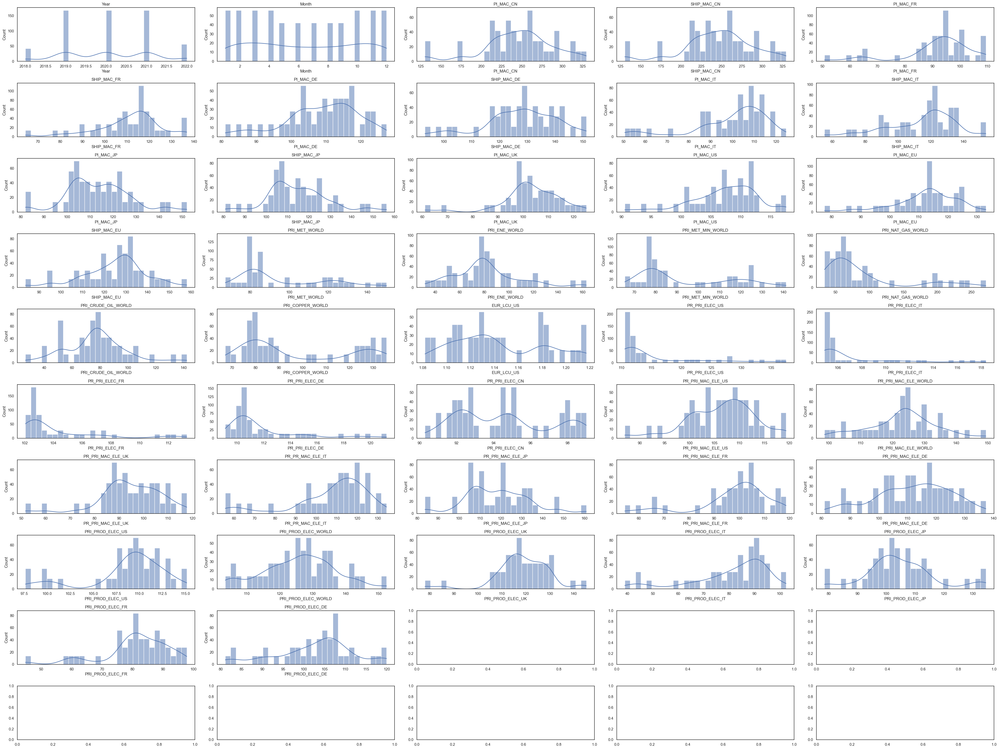

In [28]:
# Set style for better visualization
sns.set(style="white")

# Set the number of subplots
fig, axes = plt.subplots(nrows=10, ncols=5, figsize=(40, 30))

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot histograms for each numerical feature
for i, col in enumerate(numerical_features):
    sns.histplot(train_data[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

# Adjust layout
plt.tight_layout()
plt.show()

__`Step 14`__ Creating a boxplot of the numerical features.

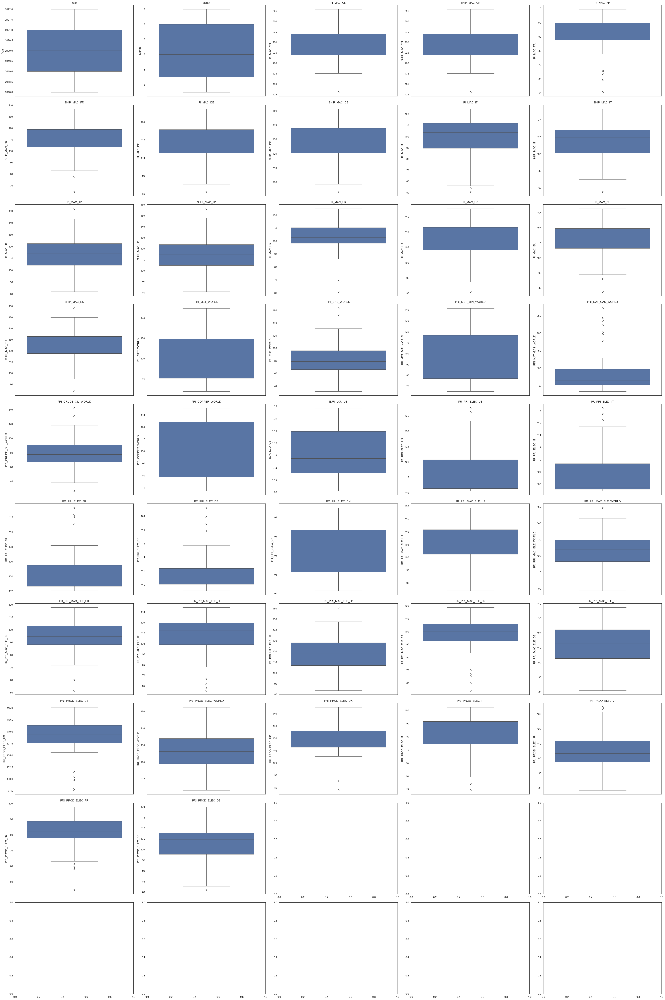

In [29]:
# Ignore warnings
warnings.simplefilter(action='ignore')

# Set style for better visualization
sns.set(style="white")

# Set the number of subplots
fig, axes = plt.subplots(nrows=10, ncols=5, figsize=(40, 60))

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot boxplots for each numerical feature
for i, col in enumerate(numerical_features):
    sns.boxplot(data=train_data, y=col, ax=axes[i])
    axes[i].set_title(col)

# Adjust layout
plt.tight_layout()
plt.show()

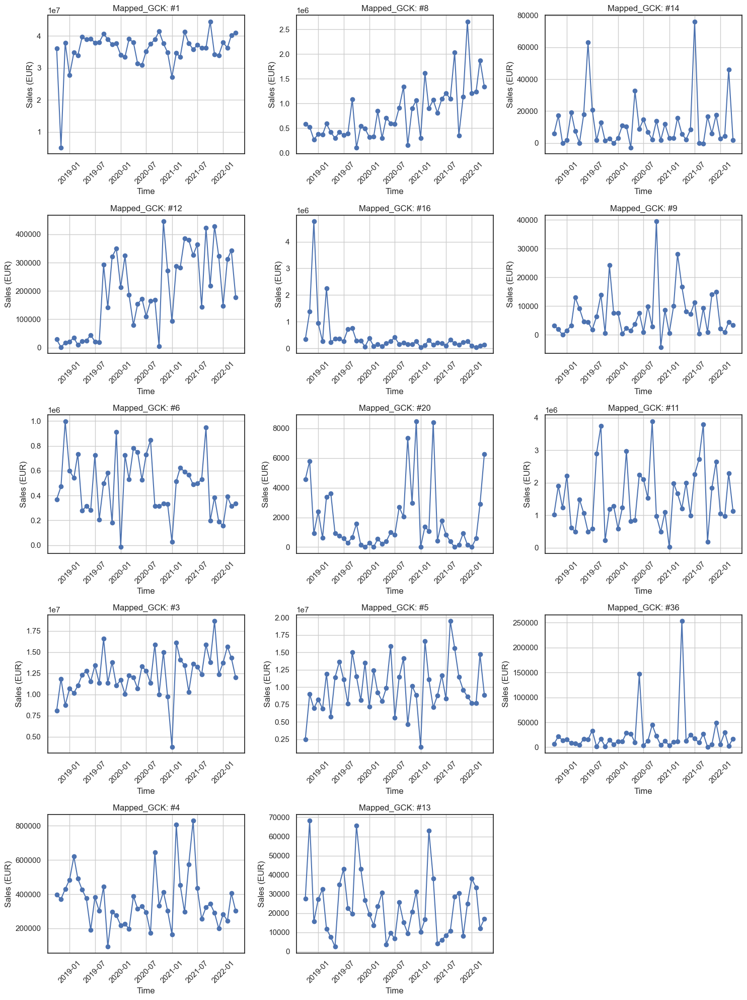

In [30]:
# Convert Year and Month into a Date column
train_data['Date'] = pd.to_datetime(train_data['Year'].astype(str) + '-' + train_data['Month'].astype(str) + '-01')

# Sort data by Date
train_data = train_data.sort_values(by='Date')

# Get unique values of Mapped_GCK (Limit to 14 unique values)
gck_values = train_data['Mapped_GCK'].unique()[:14]

# Create subplots (Arrange in a grid: 5 rows x 3 cols, adjusting for 14 plots)
fig, axes = plt.subplots(5, 3, figsize=(15, 20)) 
axes = axes.flatten()  # Flatten to iterate easily

# Iterate over each Mapped_GCK value and create a separate graph
for i, gck in enumerate(gck_values):
    ax = axes[i]
    subset = train_data[train_data['Mapped_GCK'] == gck]
    ax.plot(subset['Date'], subset['Sales_EUR'], marker='o', linestyle='-')
    ax.set_title(f'Mapped_GCK: {gck}')
    ax.set_xlabel('Time')
    ax.set_ylabel('Sales (EUR)')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True)

# Hide empty subplots if less than 15
for j in range(len(gck_values), len(axes)):
    fig.delaxes(axes[j])

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

# 3. Data Preparation

__`Step 15`__ Here we treated `Mapped_GCK` in order to divide the datasets by business unit.

In [31]:
Mapped_GCK_Numbers = train_data["Mapped_GCK"].unique().tolist()

# Removing the hashtags (#) of every element in the list
Mapped_GCK_Numbers = [int(item.replace('#', '')) for item in Mapped_GCK_Numbers]

In [32]:
# Creating a list of filtered dataframes for every unique value of "Mapped_GCK"
data_list = [train_data[train_data["Mapped_GCK"] == f"#{i}"] for i in Mapped_GCK_Numbers]

In [33]:
bi = [1, 8, 14, 12, 16, 9, 6, 20, 11, 3, 5, 36, 4, 13]

__`Step 16`__ Add `Deaths (per million)` to all of the Business units datasets.

In [34]:
for i in range(len(data_list)):
    data_list[i] = data_list[i].merge(covid[["Date", "Deaths (per million)"]], on="Date", how="left")

# 4. Modelling

__`Step 17`__ Create the a pipeline for each model we tested, (Scale, Select 20 best features, Optuna, Vizualizations).

## XGBRegressor

In [35]:
def run_rfe_then_optuna(df, n_trials=30, plot=False):
    df = df.copy()
    df["Date"] = pd.to_datetime(df["Date"])

    # Separar dados com e sem target
    df_train = df[df["Sales_EUR"].notna()]
    df_future = df[df["Sales_EUR"].isna()]

    features = df_train.drop(columns=["Sales_EUR", "Mapped_GCK", "Date", "Year", "Month"])
    target = df_train["Sales_EUR"]
    dates = df_train["Date"]

    X_train = features.iloc[:-10]
    y_train = target.iloc[:-10]
    X_val = features.iloc[-10:]
    y_val = target.iloc[-10:]
    val_dates = dates.iloc[-10:]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    base_model = XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42)
    rfe = RFE(base_model, n_features_to_select=20)
    rfe.fit(X_train_scaled, y_train)

    X_train_rfe = rfe.transform(X_train_scaled)
    X_val_rfe = rfe.transform(X_val_scaled)
    selected_features = features.columns[rfe.support_].tolist()

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
            "max_depth": trial.suggest_int("max_depth", 2, 10),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0, step=0.1),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0, step=0.1),
            "gamma": trial.suggest_float("gamma", 0, 10.0, step=0.5),
            "reg_alpha": trial.suggest_float("reg_alpha", 0, 10.0, step=0.5),
            "reg_lambda": trial.suggest_float("reg_lambda", 0, 10.0, step=0.5),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        }
        model = XGBRegressor(**params)
        model.fit(X_train_rfe, y_train)
        preds = model.predict(X_val_rfe)
        return mean_squared_error(y_val, preds, squared=False)

    study = optuna.create_study(direction="minimize")
    study.optimize(objective, n_trials=n_trials)
    best_params = study.best_params

    final_model = XGBRegressor(**best_params)
    final_model.fit(X_train_rfe, y_train)
    y_pred = final_model.predict(X_val_rfe)
    rmse = mean_squared_error(y_val, y_pred, squared=False)

    if plot and not y_val.isnull().any():
        plt.figure(figsize=(10, 4))
        plt.plot(val_dates, y_val, label="Real", marker='o')
        plt.plot(val_dates, y_pred, label="Previsto", marker='x')
        plt.title("Previsão com RFE + Optuna")
        plt.xlabel("Mês")
        plt.ylabel("Sales_EUR")
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
        plt.xticks(rotation=45)
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

    # Previsão futura se houver
    if not df_future.empty:
        X_future = df_future.drop(columns=["Sales_EUR", "Mapped_GCK", "Date", "Year", "Month"])
        X_future_scaled = scaler.transform(X_future)
        X_future_rfe = rfe.transform(X_future_scaled)
        y_future_pred = final_model.predict(X_future_rfe)
        future_dates = df_future["Date"].dt.to_period("M").astype(str)

        return None, None, y_future_pred, future_dates, best_params, selected_features

    return rmse, y_val.values, y_pred, val_dates.dt.to_period("M").astype(str), best_params, selected_features


## LGBMRegressor

In [36]:
def run_lightgbm_forecast_with_rfe_and_optuna(df, n_trials=30, plot=False):
    df = df.copy()
    df["Date"] = pd.to_datetime(df["Date"])

    # Separar dados com e sem target
    df_train = df[df["Sales_EUR"].notna()]
    df_future = df[df["Sales_EUR"].isna()]

    features = df_train.drop(columns=["Sales_EUR", "Mapped_GCK", "Date", "Year", "Month"])
    target = df_train["Sales_EUR"]
    dates = df_train["Date"]

    X_train = features.iloc[:-10]
    y_train = target.iloc[:-10]
    X_val = features.iloc[-10:]
    y_val = target.iloc[-10:]
    val_dates = dates.iloc[-10:]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    base_model = LGBMRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42)
    rfe = RFE(base_model, n_features_to_select=20)
    rfe.fit(X_train_scaled, y_train)

    X_train_rfe = rfe.transform(X_train_scaled)
    X_val_rfe = rfe.transform(X_val_scaled)

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
            "max_depth": trial.suggest_int("max_depth", 2, 10),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0, step=0.1),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0, step=0.1),
            "reg_alpha": trial.suggest_float("reg_alpha", 0, 10.0, step=0.5),
            "reg_lambda": trial.suggest_float("reg_lambda", 0, 10.0, step=0.5),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
        }
        model = LGBMRegressor(**params, verbosity = -1)
        model.fit(X_train_rfe, y_train)
        preds = model.predict(X_val_rfe)
        return mean_squared_error(y_val, preds, squared=False)

    study = optuna.create_study(direction="minimize")
    study.optimize(objective, n_trials=n_trials)
    best_params = study.best_params

    final_model = LGBMRegressor(**best_params, verbose=-1)
    final_model.fit(X_train_rfe, y_train)
    y_pred = final_model.predict(X_val_rfe)
    rmse = mean_squared_error(y_val, y_pred, squared=False)

    if plot and not y_val.isnull().any():
        plt.figure(figsize=(10, 4))
        plt.plot(val_dates, y_val, label="Real", marker='o')
        plt.plot(val_dates, y_pred, label="Previsto", marker='x')
        plt.title("Previsão com RFE + Optuna (LightGBM)")
        plt.xlabel("Mês")
        plt.ylabel("Sales_EUR")
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
        plt.xticks(rotation=45)
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

    if not df_future.empty:
        X_future = df_future.drop(columns=["Sales_EUR", "Mapped_GCK", "Date", "Year", "Month"])
        X_future_scaled = scaler.transform(X_future)
        X_future_rfe = rfe.transform(X_future_scaled)
        y_future_pred = final_model.predict(X_future_rfe)
        future_dates = df_future["Date"].dt.to_period("M").astype(str)

        return None, None, y_future_pred, future_dates, best_params, features.columns[rfe.support_].tolist()

    return rmse, y_val.values, y_pred, val_dates.dt.to_period("M").astype(str), best_params, features.columns[rfe.support_].tolist()


## SVR

In [37]:
def run_rfe_then_optuna_svr(df, n_trials=30, plot=False):

    df = df.copy()
    df["Date"] = pd.to_datetime(df["Date"])

    df_train = df[df["Sales_EUR"].notna()]
    df_future = df[df["Sales_EUR"].isna()]

    features = df_train.drop(columns=["Sales_EUR", "Mapped_GCK", "Date", "Year", "Month"])
    target = df_train["Sales_EUR"]
    dates = df_train["Date"]

    X_train = features.iloc[:-10]
    y_train = target.iloc[:-10]
    X_val = features.iloc[-10:]
    y_val = target.iloc[-10:]
    val_dates = dates.iloc[-10:]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    selector = SelectKBest(score_func=f_regression, k=20)
    X_train_selected = selector.fit_transform(X_train_scaled, y_train)
    X_val_selected = selector.transform(X_val_scaled)
    selected_features = features.columns[selector.get_support()].tolist()

    def objective(trial):
        params = {
            "C": trial.suggest_float("C", 0.01, 100.0, log=True),
            "epsilon": trial.suggest_float("epsilon", 0.01, 10.0),
            "gamma": trial.suggest_categorical("gamma", ["scale", "auto"]),
        }
        model = SVR(**params)
        model.fit(X_train_selected, y_train)
        preds = model.predict(X_val_selected)
        return mean_squared_error(y_val, preds, squared=False)

    study = optuna.create_study(direction="minimize")
    study.optimize(objective, n_trials=n_trials)
    best_params = study.best_params

    final_model = SVR(**best_params)
    final_model.fit(X_train_selected, y_train)
    y_pred = final_model.predict(X_val_selected)
    rmse = mean_squared_error(y_val, y_pred, squared=False)

    if plot and not y_val.isnull().any():
        plt.figure(figsize=(10, 4))
        plt.plot(val_dates, y_val, label="Real", marker='o')
        plt.plot(val_dates, y_pred, label="Previsto", marker='x')
        plt.title("Previsão com SVR + SelectKBest + Optuna")
        plt.xlabel("Mês")
        plt.ylabel("Sales_EUR")
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
        plt.xticks(rotation=45)
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

    if not df_future.empty:
        X_future = df_future.drop(columns=["Sales_EUR", "Mapped_GCK", "Date", "Year", "Month"])
        X_future_scaled = scaler.transform(X_future)
        X_future_selected = selector.transform(X_future_scaled)
        y_future_pred = final_model.predict(X_future_selected)
        future_dates = df_future["Date"].dt.to_period("M").astype(str)

        return None, None, y_future_pred, future_dates, best_params, selected_features

    return rmse, y_val.values, y_pred, val_dates.dt.to_period("M").astype(str), best_params, selected_features


__`Step 18`__ Create the vizualization to compare different models with the real values, and the correspondent RMSE.

In [38]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_all_bu_predictions(results_dict):
    for bu, data in results_dict.items():
        plt.figure(figsize=(10, 5))
        
        # Converter datas se ainda estiverem em Period
        dates = pd.to_datetime(data["dates"].astype(str))

        # Plot real (se disponível)
        if "real" in data and data["real"] is not None and len(data["real"]) == len(dates):
            plt.plot(dates, data["real"], label="Real", linewidth=2, marker='o')

        # Previsões
        plt.plot(dates, data["xgb"]["pred"], label="XGBoost", linestyle='--', marker='x')
        plt.plot(dates, data["lgbm"]["pred"], label="LightGBM", linestyle='--', marker='s')
        plt.plot(dates, data["svr"]["pred"], label="SVR", linestyle='--', marker='^')

        # Formatando o eixo x
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
        plt.xticks(rotation=45)
        plt.xlabel("Date")
        plt.ylabel("Sales_EUR")
        plt.title(f"Predictions vs Real - {bu}")
        plt.legend()
        plt.tight_layout()

        # Exibir RMSE apenas se disponível
        rmse_text_parts = []
        if "rmse" in data["xgb"]:
            rmse_text_parts.append(f"XGBoost: {data['xgb']['rmse']:.2f}")
        if "rmse" in data["lgbm"]:
            rmse_text_parts.append(f"LightGBM: {data['lgbm']['rmse']:.2f}")
        if "rmse" in data["svr"]:
            rmse_text_parts.append(f"SVR: {data['svr']['rmse']:.2f}")
        
        if rmse_text_parts:
            rmse_text = "RMSE " + " | ".join(rmse_text_parts)
            plt.figtext(0.5, -0.05, rmse_text, wrap=True, horizontalalignment='center', fontsize=10)

        plt.show()


__`Step 19`__ Predict the values on validation and save predictions, metrics and used features.

In [39]:
results = {}

for i, df in enumerate(data_list):
    bu_name = f"BU_{bi[i]}"
    
    # XGBoost
    rmse_xgb, y_val, y_pred_xgb, val_dates, best_params_xgb, selected_features_xgb = run_rfe_then_optuna(df, n_trials=1000)

    # LightGBM
    rmse_lgbm, _, y_pred_lgbm, _, _, _ = run_lightgbm_forecast_with_rfe_and_optuna(df, n_trials=1000)
    
    # SVR
    rmse_svr, _, y_pred_svr, _, _, _ = run_rfe_then_optuna_svr(df, n_trials=1000)
    
    # Construir dicionário para a BU
    results[bu_name] = {
        "dates": val_dates,
        "real": y_val,
        "xgb": {
            "pred": y_pred_xgb,
            "rmse": rmse_xgb,
            "selected_features": selected_features_xgb,
            "best_params": best_params_xgb
        },
        "lgbm": {
            "pred": y_pred_lgbm,
            "rmse": rmse_lgbm
        },
        "svr": {
            "pred": y_pred_svr,
            "rmse": rmse_svr
        }
    }

# Calcular e imprimir os RMSE médios
avg_rmse_xgb = np.mean([v["xgb"]["rmse"] for v in results.values()])
avg_rmse_lgbm = np.mean([v["lgbm"]["rmse"] for v in results.values()])
avg_rmse_svr = np.mean([v["svr"]["rmse"] for v in results.values()])

print(f"RMSEs Mean:")
print(f"XGBoost: {avg_rmse_xgb:.2f}")
print(f"LightGBM: {avg_rmse_lgbm:.2f}")
print(f"SVR: {avg_rmse_svr:.2f}")

# Print dos melhores parâmetros do XGBoost para cada BU
for bu, data in results.items():
    print(f"Best parameters for {bu}: {data['xgb']['best_params']}")


[I 2025-03-28 22:12:22,301] A new study created in memory with name: no-name-f0dff50e-3214-401f-8e36-c5a29d2afa10
[I 2025-03-28 22:12:22,421] Trial 0 finished with value: 5596917.408075708 and parameters: {'n_estimators': 500, 'max_depth': 10, 'learning_rate': 0.023826896406918978, 'subsample': 0.5, 'colsample_bytree': 0.6000000000000001, 'gamma': 9.5, 'reg_alpha': 7.5, 'reg_lambda': 6.0, 'min_child_weight': 3}. Best is trial 0 with value: 5596917.408075708.
[I 2025-03-28 22:12:22,501] Trial 1 finished with value: 6242635.443714632 and parameters: {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.06260925456932545, 'subsample': 0.9, 'colsample_bytree': 1.0, 'gamma': 0.5, 'reg_alpha': 1.5, 'reg_lambda': 1.0, 'min_child_weight': 9}. Best is trial 0 with value: 5596917.408075708.
[I 2025-03-28 22:12:22,602] Trial 2 finished with value: 5992751.240667701 and parameters: {'n_estimators': 450, 'max_depth': 5, 'learning_rate': 0.16396826429747932, 'subsample': 1.0, 'colsample_bytree': 

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 33, number of used features: 0
[LightGBM] [Info] Start training from score 35344126.969697
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet t

[I 2025-03-28 22:16:09,733] Trial 2 finished with value: 3830200.6150300764 and parameters: {'n_estimators': 700, 'max_depth': 3, 'learning_rate': 0.01950668851675567, 'subsample': 0.5, 'colsample_bytree': 0.9, 'reg_alpha': 2.0, 'reg_lambda': 4.5, 'min_child_samples': 8}. Best is trial 2 with value: 3830200.6150300764.
[I 2025-03-28 22:16:09,741] Trial 3 finished with value: 3947458.705493971 and parameters: {'n_estimators': 150, 'max_depth': 3, 'learning_rate': 0.13458708279428175, 'subsample': 0.8, 'colsample_bytree': 0.5, 'reg_alpha': 5.5, 'reg_lambda': 8.0, 'min_child_samples': 50}. Best is trial 2 with value: 3830200.6150300764.
[I 2025-03-28 22:16:09,751] Trial 4 finished with value: 3947458.705493971 and parameters: {'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.047107059924996295, 'subsample': 1.0, 'colsample_bytree': 0.6000000000000001, 'reg_alpha': 2.5, 'reg_lambda': 10.0, 'min_child_samples': 44}. Best is trial 2 with value: 3830200.6150300764.
[I 2025-03-28 22:16:

RMSEs Mean:
XGBoost: 689731.25
LightGBM: 766230.72
SVR: 972423.02
Best parameters for BU_1: {'n_estimators': 500, 'max_depth': 9, 'learning_rate': 0.06005534211523232, 'subsample': 0.6, 'colsample_bytree': 1.0, 'gamma': 0.5, 'reg_alpha': 2.0, 'reg_lambda': 0.5, 'min_child_weight': 1}
Best parameters for BU_8: {'n_estimators': 450, 'max_depth': 6, 'learning_rate': 0.07460764116893304, 'subsample': 0.9, 'colsample_bytree': 0.8, 'gamma': 2.0, 'reg_alpha': 2.5, 'reg_lambda': 2.0, 'min_child_weight': 1}
Best parameters for BU_14: {'n_estimators': 100, 'max_depth': 10, 'learning_rate': 0.10157570002743913, 'subsample': 0.7, 'colsample_bytree': 0.6000000000000001, 'gamma': 0.0, 'reg_alpha': 4.0, 'reg_lambda': 7.5, 'min_child_weight': 9}
Best parameters for BU_12: {'n_estimators': 150, 'max_depth': 6, 'learning_rate': 0.12010934804218065, 'subsample': 0.5, 'colsample_bytree': 0.7000000000000001, 'gamma': 9.0, 'reg_alpha': 9.5, 'reg_lambda': 3.0, 'min_child_weight': 6}
Best parameters for BU_16

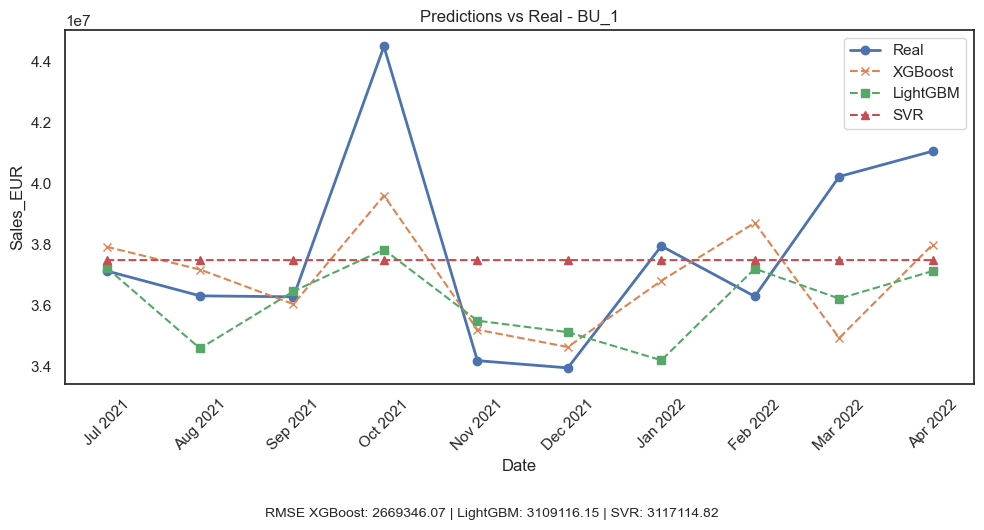

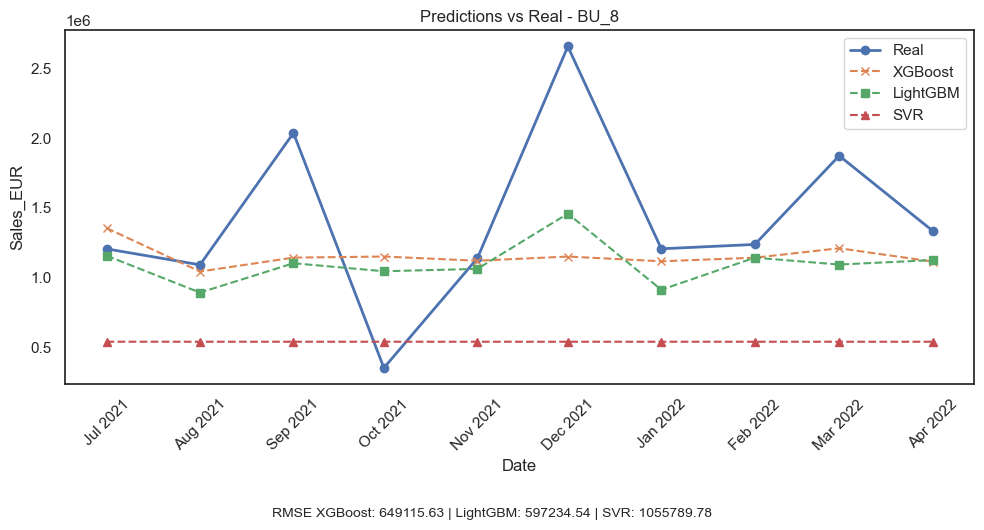

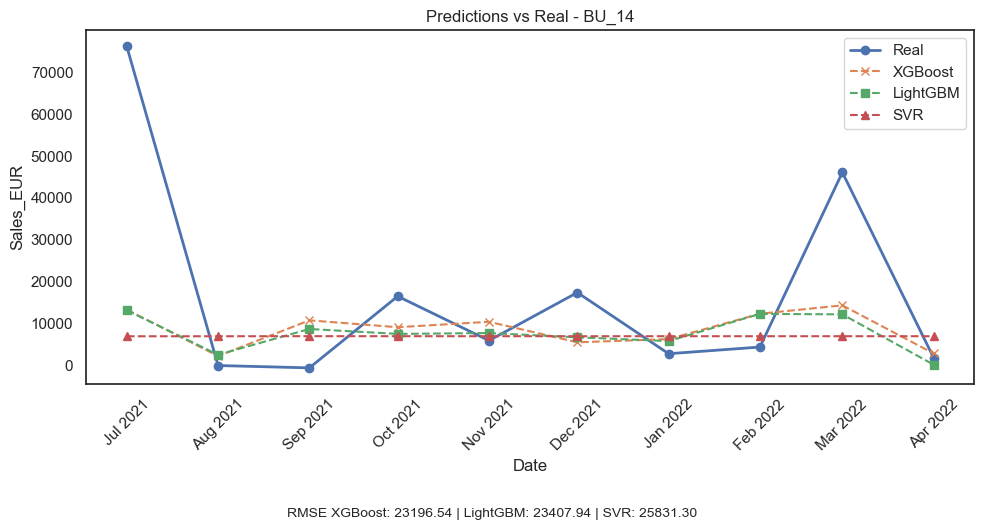

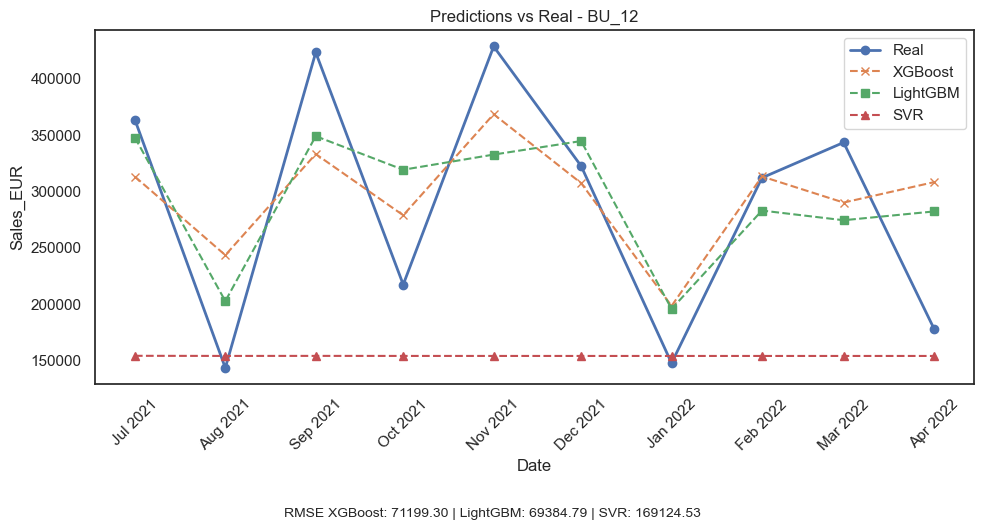

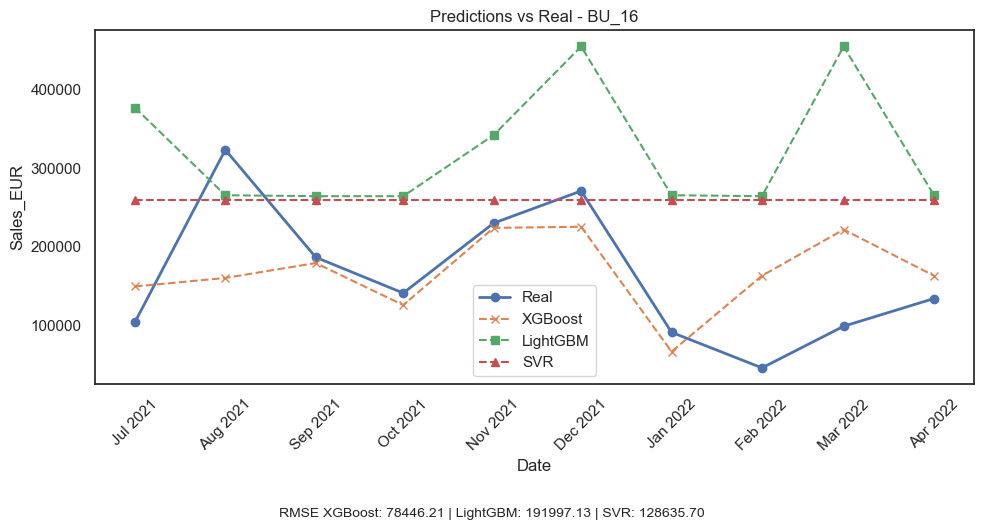

...

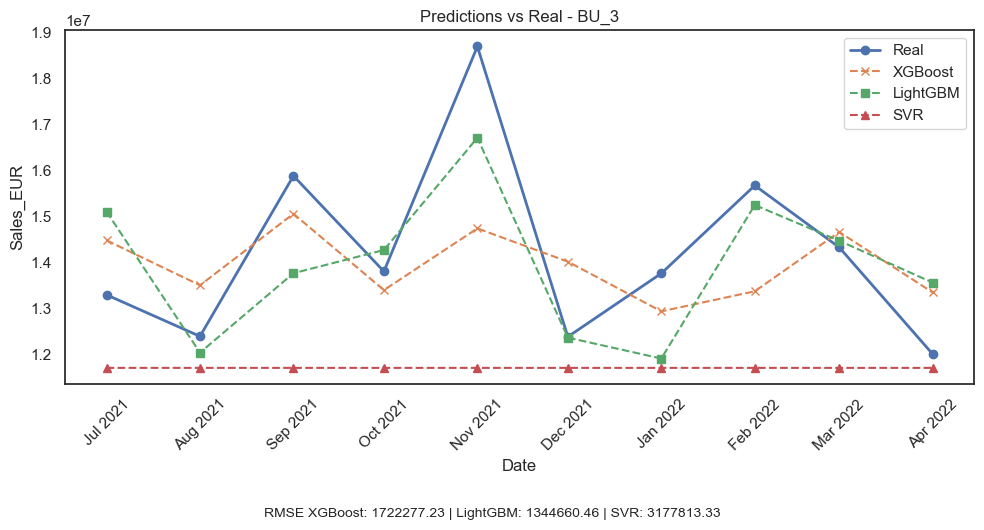

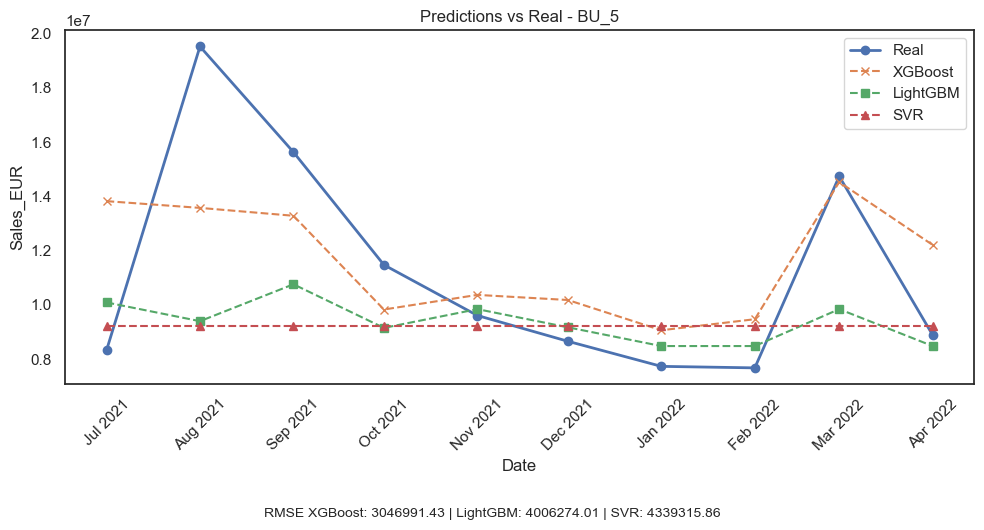

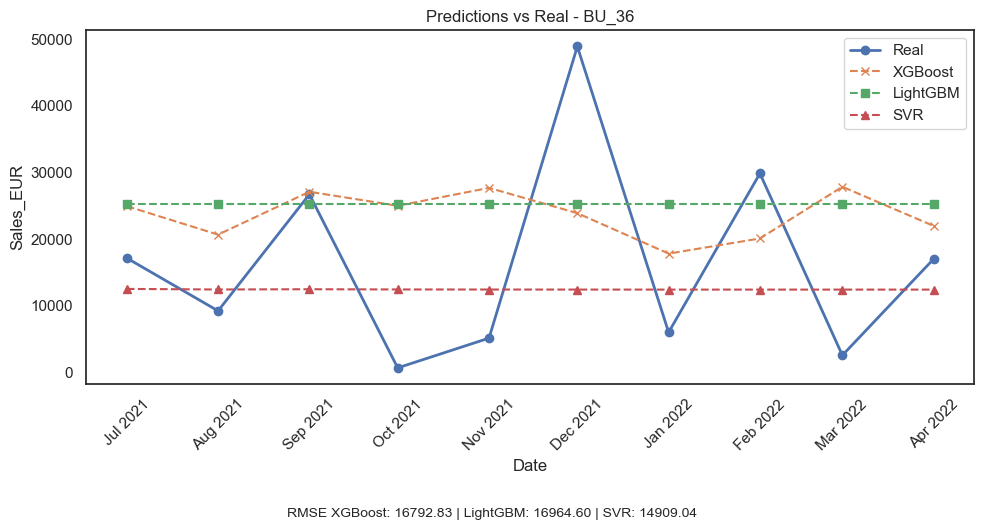

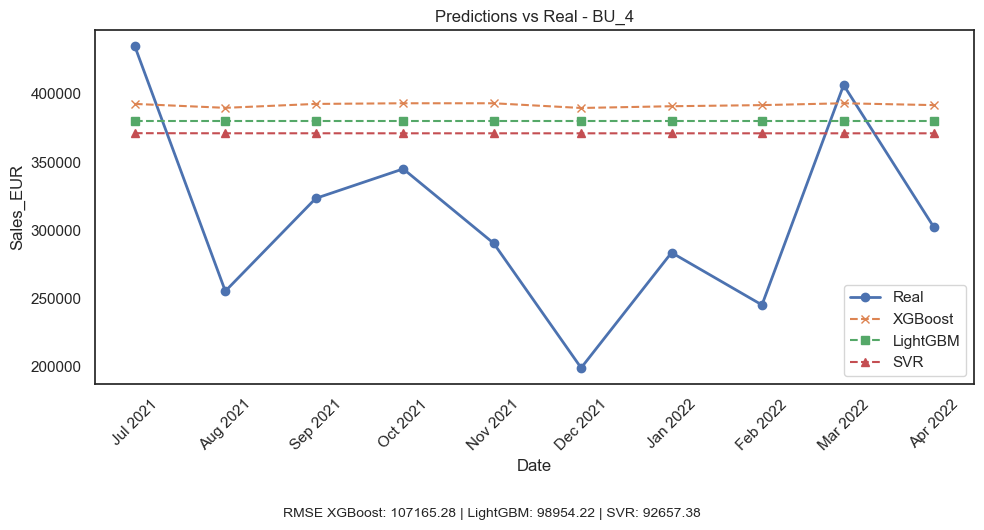

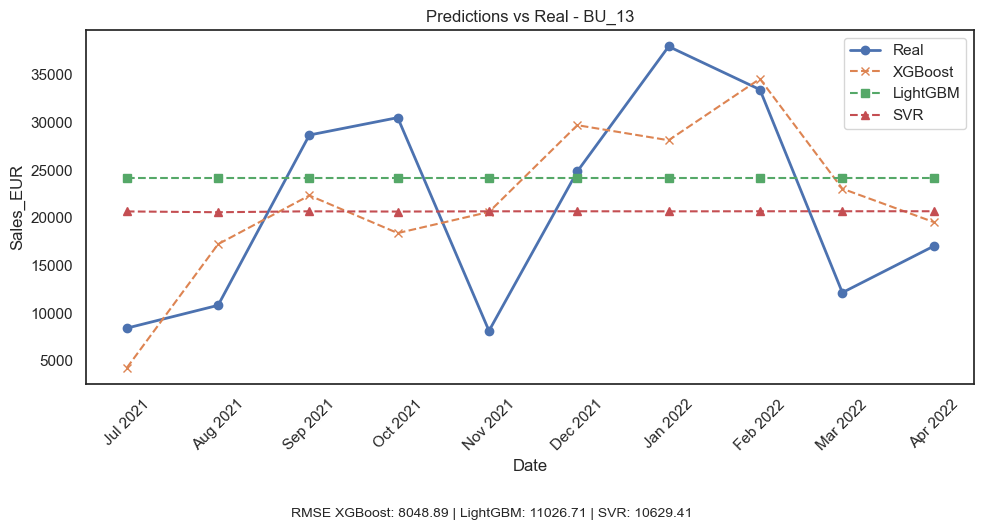

In [40]:
plot_all_bu_predictions(results)

__`Step 20`__ Analysing the 20 best features by business unit.

In [41]:
for i in range(0,14):
    print(f"Business Unit {bi[i]}: {results[f'BU_{bi[i]}']['xgb']['selected_features']}")

Business Unit 1: ['PI_MAC_CN', 'PI_MAC_FR', 'SHIP_MAC_FR', 'PI_MAC_DE', 'SHIP_MAC_DE', 'PI_MAC_IT', 'SHIP_MAC_IT', 'PI_MAC_JP', 'PI_MAC_US', 'SHIP_MAC_EU', 'PRI_MET_WORLD', 'PRI_NAT_GAS_WORLD', 'PR_PRI_ELEC_IT', 'PR_PRI_MAC_ELE_WORLD', 'PR_PRI_MAC_ELE_UK', 'PR_PRI_MAC_ELE_DE', 'PRI_PROD_ELEC_UK', 'PRI_PROD_ELEC_IT', 'PRI_PROD_ELEC_JP', 'PRI_PROD_ELEC_FR']
Business Unit 8: ['PI_MAC_CN', 'PI_MAC_FR', 'SHIP_MAC_FR', 'PI_MAC_IT', 'PI_MAC_JP', 'SHIP_MAC_JP', 'PI_MAC_US', 'SHIP_MAC_EU', 'PRI_NAT_GAS_WORLD', 'EUR_LCU_US', 'PR_PRI_ELEC_US', 'PR_PRI_ELEC_IT', 'PR_PRI_ELEC_CN', 'PR_PRI_MAC_ELE_US', 'PR_PRI_MAC_ELE_WORLD', 'PRI_PROD_ELEC_WORLD', 'PRI_PROD_ELEC_UK', 'PRI_PROD_ELEC_IT', 'PRI_PROD_ELEC_JP', 'PRI_PROD_ELEC_DE']
Business Unit 14: ['PI_MAC_DE', 'SHIP_MAC_DE', 'PI_MAC_IT', 'PI_MAC_JP', 'SHIP_MAC_JP', 'SHIP_MAC_EU', 'PRI_ENE_WORLD', 'PRI_NAT_GAS_WORLD', 'EUR_LCU_US', 'PR_PRI_ELEC_US', 'PR_PRI_ELEC_IT', 'PR_PRI_ELEC_DE', 'PR_PRI_ELEC_CN', 'PR_PR_MAC_ELE_IT', 'PR_PRI_MAC_ELE_FR', 'PR_PRI_M

In [42]:
results

{'BU_1': {'dates': 33    2021-07
  34    2021-08
  35    2021-09
  36    2021-10
  37    2021-11
  38    2021-12
  39    2022-01
  40    2022-02
  41    2022-03
  42    2022-04
  Name: Date, dtype: object,
  'real': array([37130004.21      , 36310817.42      , 36278886.58      ,
         44483013.86000001, 34187395.6       , 33950069.83      ,
         37942942.06      , 36293076.33      , 40220407.03      ,
         41053203.12      ]),
  'xgb': {'pred': array([37920272., 37172056., 36038688., 39597948., 35200472., 34634848.,
          36806092., 38705220., 34930456., 37991084.], dtype=float32),
   'rmse': 2669346.0691491426,
   'selected_features': ['PI_MAC_CN',
    'PI_MAC_FR',
    'SHIP_MAC_FR',
    'PI_MAC_DE',
    'SHIP_MAC_DE',
    'PI_MAC_IT',
    'SHIP_MAC_IT',
    'PI_MAC_JP',
    'PI_MAC_US',
    'SHIP_MAC_EU',
    'PRI_MET_WORLD',
    'PRI_NAT_GAS_WORLD',
    'PR_PRI_ELEC_IT',
    'PR_PRI_MAC_ELE_WORLD',
    'PR_PRI_MAC_ELE_UK',
    'PR_PRI_MAC_ELE_DE',
    'PRI_PROD_ELEC_U

# Deployment

In [48]:
bu_map = {
    "BU_1": "#1",
    "BU_8": "#8",
    "BU_14": "#14",
    "BU_12": "#12",
    "BU_16": "#16",
    "BU_9": "#9",
    "BU_6": "#6",
    "BU_20": "#20",
    "BU_11": "#11",
    "BU_3": "#3",
    "BU_5": "#5",
    "BU_36": "#36",
    "BU_4": "#4",
    "BU_13": "#13"
}


In [49]:
# Dictionary to store predictions for each BU
predictions = {}

for i, bu in enumerate(results.keys()):
    print(f"Processing {bu} with best parameters and selected features...")
    
    # Extract the best parameters
    best_params = results[bu]['xgb']['best_params']
    selected_features = results[bu]['xgb']['selected_features']
    
    # Get the test set corresponding to this BU
    test_set = market_pred[market_pred['Mapped_GCK'] == bu_map[bu]]

    # Prepare features for prediction, filtering to use only the selected features
    X_test = test_set[selected_features]
    
    # Fit the model using the best parameters
    model = XGBRegressor(**best_params)
    
    # Get the training data (from the data_list based on the index in bi)
    train_data = data_list[i]
    X_train = train_data[selected_features].iloc[:-10]
    y_train = train_data['Sales_EUR'].iloc[:-10]
    
    model.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    # Save predictions
    predictions[bu] = y_pred
    print(f"Predictions for {bu} completed.")


Processing BU_1 with best parameters and selected features...
Predictions for BU_1 completed.
Processing BU_8 with best parameters and selected features...
Predictions for BU_8 completed.
Processing BU_14 with best parameters and selected features...
Predictions for BU_14 completed.
Processing BU_12 with best parameters and selected features...
Predictions for BU_12 completed.
Processing BU_16 with best parameters and selected features...
Predictions for BU_16 completed.
Processing BU_9 with best parameters and selected features...
Predictions for BU_9 completed.
Processing BU_6 with best parameters and selected features...
Predictions for BU_6 completed.
Processing BU_20 with best parameters and selected features...
Predictions for BU_20 completed.
Processing BU_11 with best parameters and selected features...
Predictions for BU_11 completed.
Processing BU_3 with best parameters and selected features...
Predictions for BU_3 completed.
Processing BU_5 with best parameters and selected 

In [50]:
predictions

{'BU_1': array([37784836., 35054588., 38184680., 38224688., 35851276., 38034444.,
        35973740., 35049584., 37375948., 37691624.], dtype=float32),
 'BU_8': array([1092330.6, 1202933.5, 1092487.4, 1099964.2, 1297325.2, 1135197.9,
        1149894.9, 1186134.5, 1085351.8, 1104239.1], dtype=float32),
 'BU_14': array([10243.703 , 15647.046 , 15450.244 ,  2298.8796, 14795.81  ,
        13614.876 , 12776.772 ,  7348.5464,  2542.5354, 12931.356 ],
       dtype=float32),
 'BU_12': array([355693.8 , 284287.03, 262211.84, 272108.9 , 261238.14, 275556.84,
        318028.84, 308362.47, 264137.25, 319243.84], dtype=float32),
 'BU_16': array([136460.94, 159480.4 , 125747.75, 160267.14, 189282.61, 125747.75,
        179249.1 , 223436.06, 145042.31, 163113.3 ], dtype=float32),
 'BU_9': array([7380.2905, 9895.791 , 6227.136 , 5014.8164, 8363.189 , 7267.3857,
        6593.4487, 9362.956 , 5752.1167, 5693.8105], dtype=float32),
 'BU_6': array([373282.53, 441240.62, 555336.6 , 316290.44, 432306.56, 432

In [ ]:
for bu, bu_num in bu_map.items():
    mask = test["Mapped_GCK"] == bu_num

    preds = predictions[bu]
    
    if len(preds) == mask.sum():
        test.loc[mask, "Sales_EUR"] = preds

  Month Year Mapped_GCK   Sales_EUR
0     Mai 22         #3  13478198.0
1     Jun 22         #3  14497057.0
2     Jul 22         #3  14380463.0
3     Aug 22         #3  14227980.0
4     Sep 22         #3  15121102.0


In [52]:
test

,Month Year,Mapped_GCK,Sales_EUR
0,Mai 22,#3,13478198.0
1,Jun 22,#3,14497057.0
2,Jul 22,#3,14380463.0
3,Aug 22,#3,14227980.0
4,Sep 22,#3,15121102.0
...,...,...,...
135,Okt 22,#1,38034444.0
136,Nov 22,#1,35973740.0
137,Dez 22,#1,35049584.0
138,Jan 23,#1,37375948.0


In [53]:
test.to_csv("final_prediction.csv", index=False)